# Your Week as a Portfolio

This notebook goes with the post *Everything You Do Is a Portfolio and You Are
Managing It Badly*.

**The idea.** Allocating hours across the things you care about is the same
mathematical problem as allocating money across assets. Same inputs: expected
returns, variances, covariances. Same optimiser. Same failure mode.

**What gets built.** A six by six covariance matrix over six weekly activities,
then three allocations: the unconstrained optimiser, the same optimiser with a no
short constraint, and naive equal weighting. Then an out of sample test of all
three on a later period none of them has seen.

**About the data.** The weekly data here is constructed, not measured. Nobody has
a real dataset of life satisfaction per hour, and inventing one and calling it
real would be worse than inventing one and saying so. The numbers are chosen to
behave the way the real version behaves, and the point of the notebook is the
machinery, not the figures.

Run this top to bottom on a fresh kernel.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

import sys, scipy
print(f"python {sys.version.split()[0]}")
print(f"numpy  {np.__version__}")
print(f"pandas {pd.__version__}")
print(f"scipy  {scipy.__version__}")

BLUE, ORANGE, INK, GREY = "#4C6EF5", "#E8590C", "#212529", "#868E96"
SEED = 20261012

python 3.12.2
numpy  1.26.4
pandas 2.2.2
scipy  1.13.1


## Building the data

Six activities. For each week, a number standing for how much that activity gave
back per hour spent on it. Think of it as a weekly rating.

Three things are deliberately built in, because all three are true of real life
and all three matter to the optimiser.

Sleep has a modest average return and very low variance. It pays out reliably and
unspectacularly, which is exactly why it is the first thing people cut.

The side project is a lottery ticket. Low average, enormous variance. Most weeks
it produces nothing and occasionally it produces a lot.

And the activities are correlated. Sleep lifts everything else, so it is positively
correlated with the lot. Work and the side project compete for the same energy, so
they move against each other. Exercise and friends tend to move together, because
the weeks you have capacity for one are the weeks you have capacity for both.

In [2]:
ACTIVITIES = ["Work", "Sleep", "Exercise", "Friends", "Side project", "Admin"]
N = len(ACTIVITIES)

# true expected return per hour, and true volatility
TRUE_MEAN = np.array([0.22, 0.18, 0.16, 0.20, 0.12, 0.08])
TRUE_VOL  = np.array([1.00, 0.45, 0.70, 0.90, 2.00, 0.55])

# true correlation structure
CORR = np.array([
    #  Work  Sleep  Exer  Frnd  Side  Admin
    [  1.00,  0.30, 0.10, -0.10, -0.35,  0.20],  # Work
    [  0.30,  1.00, 0.45,  0.35,  0.15,  0.10],  # Sleep lifts everything
    [  0.10,  0.45, 1.00,  0.50,  0.05,  0.00],  # Exercise
    [ -0.10,  0.35, 0.50,  1.00,  0.00, -0.05],  # Friends
    [ -0.35,  0.15, 0.05,  0.00,  1.00, -0.10],  # Side project competes with Work
    [  0.20,  0.10, 0.00, -0.05, -0.10,  1.00],  # Admin
])

TRUE_COV = np.outer(TRUE_VOL, TRUE_VOL) * CORR

# eigenvalues must all be positive or the matrix is not a valid covariance matrix
print("smallest eigenvalue:", np.linalg.eigvalsh(TRUE_COV).min().round(5))

smallest eigenvalue: 0.11564


That eigenvalue check matters. A covariance matrix has to be positive
semi-definite, which in plain terms means the correlations have to be mutually
consistent. You cannot have A strongly positive with B, B strongly positive with
C, and A strongly negative with C. If you invent correlations by hand without
checking, you can easily write down a matrix describing a world that cannot exist,
and the optimiser will happily produce an answer from it.

In [3]:
rng = np.random.default_rng(SEED)

WEEKS_TRAIN = 10   # the sample you estimate from
WEEKS_TEST  = 40   # the later period nothing has seen

def draw_weeks(n_weeks, rng):
    return pd.DataFrame(
        rng.multivariate_normal(TRUE_MEAN, TRUE_COV, size=n_weeks),
        columns=ACTIVITIES,
    )

train = draw_weeks(WEEKS_TRAIN, rng)
test  = draw_weeks(WEEKS_TEST, rng)

print(f"{WEEKS_TRAIN} weeks to estimate from, {WEEKS_TEST} weeks to test on")
train.round(2)

10 weeks to estimate from, 40 weeks to test on


,Work,Sleep,Exercise,Friends,Side project,Admin
0,-0.31,0.33,0.71,0.23,2.77,0.14
1,-0.05,-0.50,-1.35,-1.36,0.87,0.64
2,-1.29,0.10,-0.04,-0.79,2.48,-0.79
3,1.08,0.63,1.90,1.92,-0.77,-0.17
4,0.54,-0.33,-0.24,-1.95,0.72,1.23
5,0.39,0.27,-0.43,-0.16,1.83,0.31
6,0.21,-0.19,-0.43,-1.02,-3.23,-0.49
7,0.85,-0.06,0.47,0.49,0.98,0.36
8,-1.39,-0.23,-0.61,-1.00,0.53,1.17
9,-0.11,0.65,-0.53,0.55,-2.30,1.35


Ten weeks is a small sample, and that is the point. It is roughly how much
evidence anyone actually has when they decide their life needs restructuring. Two
good months at the gym, a quarter where the job went well.

## What the sample says versus what is true

The optimiser only ever sees the sample. Here is how far the sample is from the
truth it was drawn from.

In [4]:
comparison = pd.DataFrame({
    "true mean": TRUE_MEAN,
    "sample mean": train.mean().values,
    "error": train.mean().values - TRUE_MEAN,
}, index=ACTIVITIES)

comparison.round(3)

,true mean,sample mean,error
Work,0.22,-0.009,-0.229
Sleep,0.18,0.065,-0.115
Exercise,0.16,-0.055,-0.215
Friends,0.20,-0.308,-0.508
Side project,0.12,0.388,0.268
Admin,0.08,0.374,0.294


Look at which activity the sample happens to rank highest, and compare it with
which one is truly highest. If they differ, the optimiser is about to be misled,
and it has no way of knowing.

## The covariance matrix

This is the object the optimiser leans on hardest. The diagonal holds each
activity's variance. Everything else holds the covariance between a pair. For six
activities there are fifteen distinct pairs to estimate, from ten weeks of data.

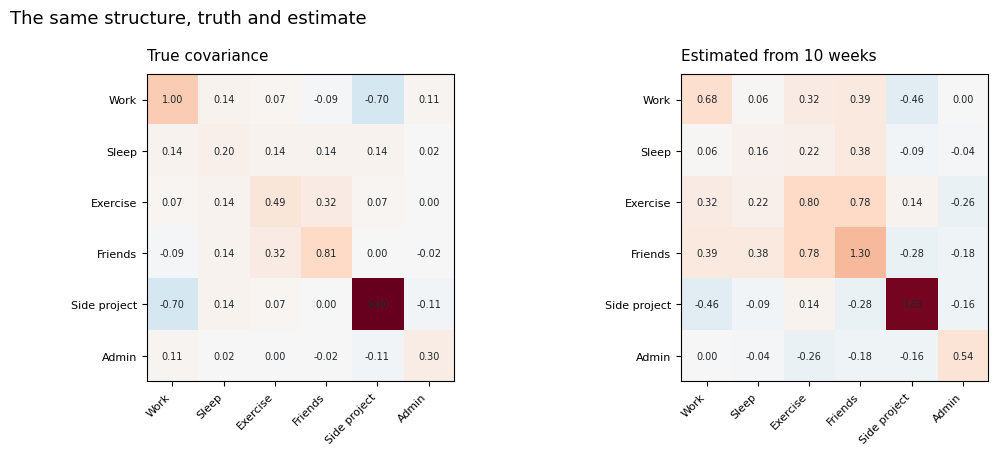

In [5]:
sample_cov = train.cov()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))

for ax, mat, label in zip(
    axes,
    [pd.DataFrame(TRUE_COV, index=ACTIVITIES, columns=ACTIVITIES), sample_cov],
    ["True covariance", f"Estimated from {WEEKS_TRAIN} weeks"],
):
    vmax = np.abs(TRUE_COV).max()
    im = ax.imshow(mat.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_xticks(range(N)); ax.set_xticklabels(ACTIVITIES, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(N)); ax.set_yticklabels(ACTIVITIES, fontsize=8)
    ax.set_title(label, fontsize=11, loc="left", pad=10)
    for i in range(N):
        for j in range(N):
            ax.text(j, i, f"{mat.values[i, j]:.2f}", ha="center", va="center",
                    fontsize=7, color=INK)

fig.suptitle("The same structure, truth and estimate", fontsize=13, x=0.02, ha="left")
fig.tight_layout()
fig.savefig("covariance_comparison.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

The two grids are describing the same world. One of them is the world, the other
is what ten weeks of it looked like. Every number the optimiser uses comes from
the right-hand grid.

## The optimiser

Mean-variance optimisation maximises return per unit of risk. The quantity being
maximised is the ratio of expected portfolio return to portfolio volatility, which
is the Sharpe ratio from the last post, applied to a whole allocation rather than a
single investment.

Two versions are built below. The unconstrained one requires only that the weights
sum to one, so a weight is free to go negative. The constrained one additionally
requires every weight to be zero or positive, which is the version that corresponds
to a week you could actually live.

In [6]:
def portfolio_stats(w, mu, cov):
    ret = w @ mu
    vol = np.sqrt(w @ cov @ w)
    return ret, vol


def negative_sharpe(w, mu, cov):
    ret, vol = portfolio_stats(w, mu, cov)
    return -ret / vol


def optimise(mu, cov, allow_negative):
    n = len(mu)
    start = np.full(n, 1 / n)
    sum_to_one = {"type": "eq", "fun": lambda w: w.sum() - 1}
    bounds = [(-1.0, 2.0)] * n if allow_negative else [(0.0, 1.0)] * n

    result = minimize(negative_sharpe, start, args=(mu, cov),
                      method="SLSQP", bounds=bounds,
                      constraints=[sum_to_one],
                      options={"maxiter": 1000, "ftol": 1e-12})
    if not result.success:
        raise RuntimeError(result.message)
    return result.x


mu_hat = train.mean().values
cov_hat = train.cov().values

w_free   = optimise(mu_hat, cov_hat, allow_negative=True)
w_long   = optimise(mu_hat, cov_hat, allow_negative=False)
w_equal  = np.full(N, 1 / N)

weights = pd.DataFrame(
    {"Unconstrained": w_free, "No short allowed": w_long, "Equal weight": w_equal},
    index=ACTIVITIES,
)
(weights * 100).round(1)

,Unconstrained,No short allowed,Equal weight
Work,10.4,1.7,16.7
Sleep,96.8,41.5,16.7
Exercise,16.4,0.0,16.7
Friends,-44.1,0.0,16.7
Side project,3.0,9.3,16.7
Admin,17.7,47.5,16.7


Read the unconstrained column first. It concentrates the overwhelming majority of
the week into one or two activities, assigns almost nothing to several others, and
takes a large negative position in whichever activity the sample made look worst.

A negative weight is a short position. In a week it means extracting hours from
that activity to fund something else, which for most of these is not a thing a
person can do. The arithmetic is correct. Nothing in the model knows that a week
has a floor.

Now compare that column against the sample errors two cells above. The activity it
piled into is the one the sample overstated, and the one it shorted is the one the
sample understated. The optimiser did not find the best activity. It found the
largest estimation error and bet on it.

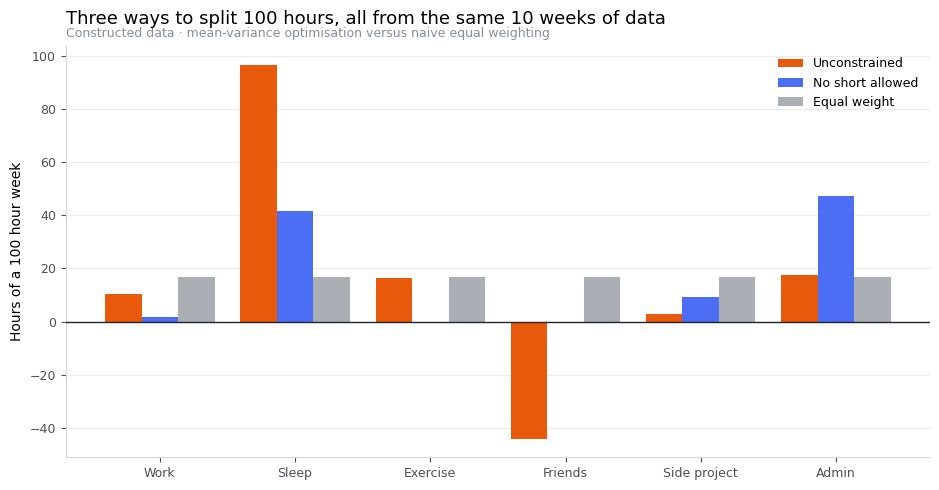

In [7]:
HOURS = 100

fig, ax = plt.subplots(figsize=(9.5, 5))

x = np.arange(N)
width = 0.27

ax.bar(x - width, weights["Unconstrained"] * HOURS, width,
       color=ORANGE, label="Unconstrained", zorder=3)
ax.bar(x, weights["No short allowed"] * HOURS, width,
       color=BLUE, label="No short allowed", zorder=3)
ax.bar(x + width, weights["Equal weight"] * HOURS, width,
       color=GREY, alpha=0.7, label="Equal weight", zorder=3)

ax.axhline(0, color=INK, linewidth=1.0, zorder=4)

ax.set_xticks(x)
ax.set_xticklabels(ACTIVITIES, fontsize=9)
ax.set_ylabel(f"Hours of a {HOURS} hour week", fontsize=10)
ax.set_title(f"Three ways to split {HOURS} hours, all from the same {WEEKS_TRAIN} weeks of data",
             fontsize=13, pad=16, loc="left")
ax.text(0, 1.015,
        "Constructed data · mean-variance optimisation versus naive equal weighting",
        transform=ax.transAxes, fontsize=9, color=GREY, va="bottom")

ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#CED4DA")
ax.tick_params(colors="#495057", labelsize=9)
ax.grid(axis="y", alpha=0.25, linewidth=0.7)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("allocations.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## The test that counts

Each allocation was built from the first ten weeks. Now run all three forward
through forty weeks none of them has seen, and compare.

Measuring performance on the data you estimated from tells you nothing. It is
checking whether a key opens the lock it was cut for.

In [8]:
def evaluate(w, data):
    weekly = data.values @ w
    return {
        "mean weekly return": weekly.mean(),
        "volatility": weekly.std(ddof=1),
        "return per unit risk": weekly.mean() / weekly.std(ddof=1),
        "worst week": weekly.min(),
    }


results = pd.DataFrame(
    {name: evaluate(weights[name].values, test) for name in weights.columns}
).T

print(f"Out of sample, {WEEKS_TEST} weeks never seen by any of the three\n")
results.round(3)

Out of sample, 40 weeks never seen by any of the three



,mean weekly return,volatility,return per unit risk,worst week
Unconstrained,0.224,0.491,0.457,-0.987
No short allowed,0.132,0.345,0.384,-0.646
Equal weight,0.225,0.423,0.532,-0.843


In [9]:
# the same three judged on the data they were built from, for contrast
in_sample = pd.DataFrame(
    {name: evaluate(weights[name].values, train) for name in weights.columns}
).T

summary = pd.DataFrame({
    "in sample": in_sample["return per unit risk"],
    "out of sample": results["return per unit risk"],
})
summary["drop"] = summary["out of sample"] - summary["in sample"]
summary.round(3)

,in sample,out of sample,drop
Unconstrained,1.062,0.457,-0.605
No short allowed,0.633,0.384,-0.249
Equal weight,0.152,0.532,0.379


The gap between those two columns is the whole argument.

In sample, the optimiser wins comfortably, because it was built to fit that data
and fitting is what it does. Out of sample, the advantage shrinks or reverses, and
the strategy that estimated nothing loses nothing.

Equal weighting barely moves between the two columns. It had no estimates to be
wrong about.

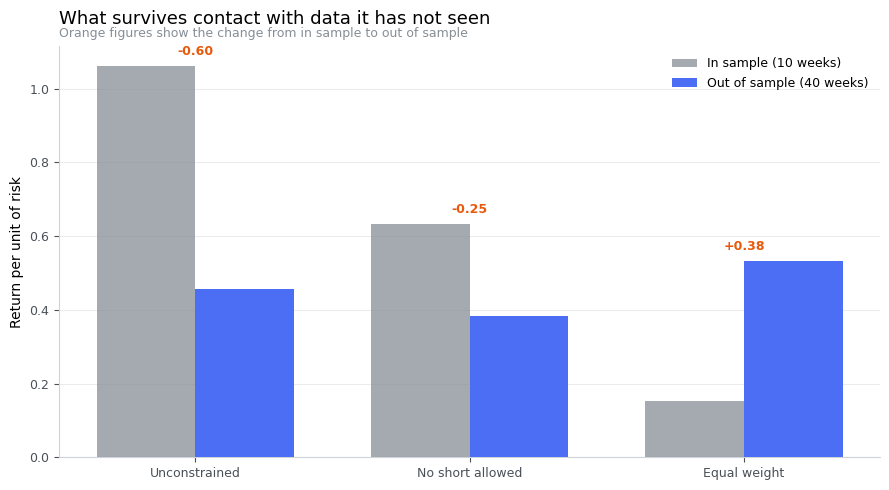

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(summary))
width = 0.36

ax.bar(x - width/2, summary["in sample"], width, color=GREY, alpha=0.75,
       label=f"In sample ({WEEKS_TRAIN} weeks)", zorder=3)
ax.bar(x + width/2, summary["out of sample"], width, color=BLUE,
       label=f"Out of sample ({WEEKS_TEST} weeks)", zorder=3)

for i, name in enumerate(summary.index):
    hi = max(summary.loc[name, "in sample"], summary.loc[name, "out of sample"])
    ax.annotate(f"{summary.loc[name, 'drop']:+.2f}", xy=(i, hi),
                xytext=(0, 8), textcoords="offset points", ha="center",
                fontsize=9, color=ORANGE, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(summary.index, fontsize=10)
ax.set_ylabel("Return per unit of risk", fontsize=10)
ax.set_title("What survives contact with data it has not seen",
             fontsize=13, pad=16, loc="left")
ax.text(0, 1.015,
        "Orange figures show the change from in sample to out of sample",
        transform=ax.transAxes, fontsize=9, color=GREY, va="bottom")

ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#CED4DA")
ax.tick_params(colors="#495057", labelsize=9)
ax.grid(axis="y", alpha=0.25, linewidth=0.7)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("out_of_sample.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## One sample is not evidence

Everything above rests on one draw of ten weeks. That is the same mistake the first
post on this blog was about, so it would be careless to stop here.

The cell below repeats the entire exercise a thousand times. Fresh ten weeks to
estimate from, fresh forty weeks to test on, three allocations built and judged,
every time.

In [11]:
N_TRIALS = 1_000
rng_trials = np.random.default_rng(SEED + 1)

records = []
for _ in range(N_TRIALS):
    tr = draw_weeks(WEEKS_TRAIN, rng_trials)
    te = draw_weeks(WEEKS_TEST, rng_trials)
    mu_t, cov_t = tr.mean().values, tr.cov().values
    try:
        cand = {
            "Unconstrained": optimise(mu_t, cov_t, True),
            "No short allowed": optimise(mu_t, cov_t, False),
            "Equal weight": w_equal,
        }
    except RuntimeError:
        continue
    records.append({k: evaluate(v, te)["return per unit risk"] for k, v in cand.items()})

trials = pd.DataFrame(records)
print(f"{len(trials):,} trials completed\n")
print(trials.describe().loc[["mean", "std", "min", "max"]].round(3))
print()
for col in ["Unconstrained", "No short allowed"]:
    beat = (trials[col] > trials["Equal weight"]).mean() * 100
    print(f"{col:18} beat equal weighting in {beat:.1f}% of trials")

/opt/anaconda3/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)


995 trials completed

      Unconstrained  No short allowed  Equal weight
mean          0.213             0.330         0.364
std           0.197             0.184         0.174
min          -0.450            -0.398        -0.315
max           0.969             0.960         1.070

Unconstrained      beat equal weighting in 24.9% of trials
No short allowed   beat equal weighting in 41.2% of trials


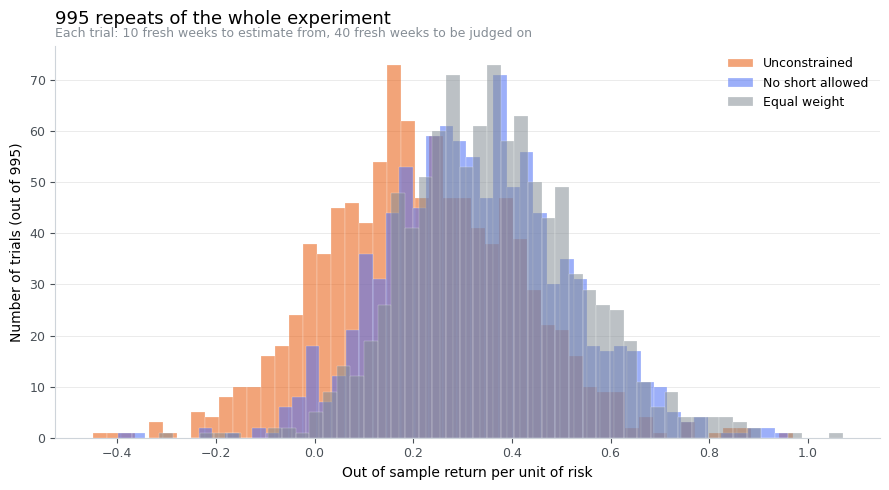

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))

colours = {"Unconstrained": ORANGE, "No short allowed": BLUE, "Equal weight": GREY}

for col in trials.columns:
    ax.hist(trials[col], bins=50, alpha=0.55, label=col,
            color=colours[col], edgecolor="white", linewidth=0.3, zorder=3)

ax.set_xlabel("Out of sample return per unit of risk", fontsize=10)
ax.set_ylabel(f"Number of trials (out of {len(trials):,})", fontsize=10)
ax.set_title(f"{len(trials):,} repeats of the whole experiment",
             fontsize=13, pad=16, loc="left")
ax.text(0, 1.015,
        f"Each trial: {WEEKS_TRAIN} fresh weeks to estimate from, {WEEKS_TEST} fresh weeks to be judged on",
        transform=ax.transAxes, fontsize=9, color=GREY, va="bottom")

ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#CED4DA")
ax.tick_params(colors="#495057", labelsize=9)
ax.grid(axis="y", alpha=0.25, linewidth=0.7)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("trial_distributions.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

Three things to read off those numbers.

Equal weighting has the highest average out of sample, and it wins most of the
time. The strategy that estimated nothing beat the one that estimated everything,
on data neither had seen, across a thousand independent repeats.

The no short constraint recovers a large part of the gap. Forbidding negative
weights limits how hard the optimiser can act on a bad estimate, and that single
restriction moves it most of the way back toward equal weighting. There is a result
in the literature showing that a no short constraint functions as a crude form of
shrinkage, and it is visible here on its own.

Equal weighting also has the narrowest spread. It is not trying to be clever, so
there is very little for it to get wrong, and it behaves about the same whatever
the sample happened to look like.

## What this does not show

The data is constructed, so none of these numbers describe anyone's actual life.
What the notebook demonstrates is the mechanism, and the mechanism is real and well
documented on market data.

The result also depends heavily on the sample size. Ten weeks is deliberately
small. Change `WEEKS_TRAIN` to a hundred and the optimiser starts winning, because
with enough data the estimates stop being noise. That is worth doing before you
conclude anything, and it is the honest version of the argument: optimisation is
not broken, it is demanding about how much evidence it needs, and people routinely
give it far less than that.

Four ways the analogy breaks, none of which the model knows about. Returns from
hours diminish and the model assumes they scale. Hours are lumpy, not continuous.
The activities are not independent of your allocation, since spending twenty hours
on something changes what the twenty-first is worth. And a week is not a repeated
independent draw from a fixed distribution, which is the assumption underneath
every line of this.

## Takeaway

The optimiser is not wrong. It answers precisely the question it was asked, using
exactly the numbers it was given.

The numbers were guesses. Nobody told it that.

Next, the same comparison on real market data, split by market condition, which is
the research this toy was built to explain.